# Fixed → Free Boundary: NCSX example

Demonstrates `fix2free`:
1. Build a fixed-boundary SPECTRE input from the NCSX VMEC wout.
2. Load NCSX coils from simsopt's built-in zoo.
3. Extend the plasma boundary outward to create a computational boundary.
4. Convert to free-boundary and write `freeb_ncsx.toml`.
5. Inspect the mode spectrum and boundary cross-sections.
6. Try running SPECTRE (a fresh object resets Fortran-side memory).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from simsopt.mhd import Vmec
from simsopt.configs.zoo import get_data

from simsopt.field import BiotSavart
from simsopt.geo import QfmResidual, QfmSurface, ToroidalFlux


from spectre import SPECTRE
from spectre.converters import simsvmec2spectre, compare_vmec_spectre
from spectre.converters.fix2free import (
    fix2free,
    params_to_simsopt_boundary,
    plot_freeboundary_modes,
)

/home/smiet/code/pyoculus/pyoculus/fields/two_waves.py:111: SyntaxWarning: invalid escape sequence '\ '
  """! Convert coordinates for Poincare plots
/home/smiet/code/pyoculus/pyoculus/maps/tokamap.py:111: SyntaxWarning: invalid escape sequence '\p'
  """
/home/smiet/code/pyoculus/pyoculus/maps/standard_map.py:90: SyntaxWarning: invalid escape sequence '\p'
  """
/home/smiet/code/pyoculus/pyoculus/solvers/manifold.py:264: SyntaxWarning: invalid escape sequence '\S'
  """
/home/smiet/code/pyoculus/pyoculus/solvers/qfm.py:96: SyntaxWarning: invalid escape sequence '\l'
  """! Convert a boundary surface to have straight field line
/home/smiet/code/pyoculus/pyoculus/solvers/qfm.py:134: SyntaxWarning: invalid escape sequence '\l'
  """! Convert a boundary surface to have straight field line, internal function
/home/smiet/code/pyoculus/pyoculus/solvers/qfm.py:204: SyntaxWarning: invalid escape sequence '\z'
  """! Construct a QFM surface based on Stuart's method, for a given orbit periodicit

## Step 1 – Fixed-boundary SPECTRE input from VMEC wout

In [2]:
simsvmec2spectre?

Signature:
simsvmec2spectre(
    vmec_obj,
    tfluxes=None,
    nvol=None,
    mpol=None,
    ntor=None,
    current_mode='volume',
    profile_type=None,
    filename=None,
    plot=False,
    angle_fix=True,
    interface_guess=None,
    map2disc_kwargs=None,
)
Docstring:
Generate a SPECTRE input from a simsopt VMEC equilibrium.

Reads pressure, rotational-transform or current profiles and the plasma
boundary from a simsopt :class:`~simsopt.mhd.Vmec` object, discretises
them onto a set of SPECTRE interfaces, and optionally writes the result to
a TOML file.

Supports both VMEC ``input.*`` files (``vmec_obj.indata``) and
``wout_*.nc`` output files (``vmec_obj.wout``).  Only ``power_series``
current profiles are supported.

Args:
    vmec_obj: simsopt ``Vmec`` instance.
    tfluxes: 1-D array-like of interface toroidal-flux values in (0, 1].
        Mutually exclusive with ``nvol``.  If ``tfluxes[-1] < 1``, the
        outermost SPECTRE interface is interior to the VMEC plasma
        

In [3]:
vmec = Vmec("wout_li383_low_res_reference.nc")
params = simsvmec2spectre(vmec, nvol=4, mpol=11, ntor=9, current_mode='volume', interface_guess="wout")
print(f"nvol={params.physics.nvol}, mpol={params.physics.mpol}, ntor={params.physics.ntor}")
print(f"lfreebound={params.physics.lfreebound}, lconstraint={params.physics.lconstraint}")

nvol=4, mpol=11, ntor=9
lfreebound=0, lconstraint=3


In [4]:
params.physics.ivolume

array([ 5818.4057329 , 20142.01541064, 44833.42689455, 61379.25480625,
           0.        ,     0.        ,     0.        ,     0.        ,
           0.        ,     0.        ,     0.        ,     0.        ,
           0.        ,     0.        ,     0.        ,     0.        ,
           0.        ,     0.        ,     0.        ,     0.        ,
           0.        ,     0.        ,     0.        ,     0.        ,
           0.        ,     0.        ,     0.        ,     0.        ,
           0.        ,     0.        ,     0.        ,     0.        ,
           0.        ,     0.        ,     0.        ,     0.        ,
           0.        ,     0.        ,     0.        ,     0.        ,
           0.        ,     0.        ,     0.        ,     0.        ,
           0.        ,     0.        ,     0.        ,     0.        ,
           0.        ,     0.        ,     0.        ,     0.        ,
           0.        ,     0.        ,     0.        ,     0.        ,
      

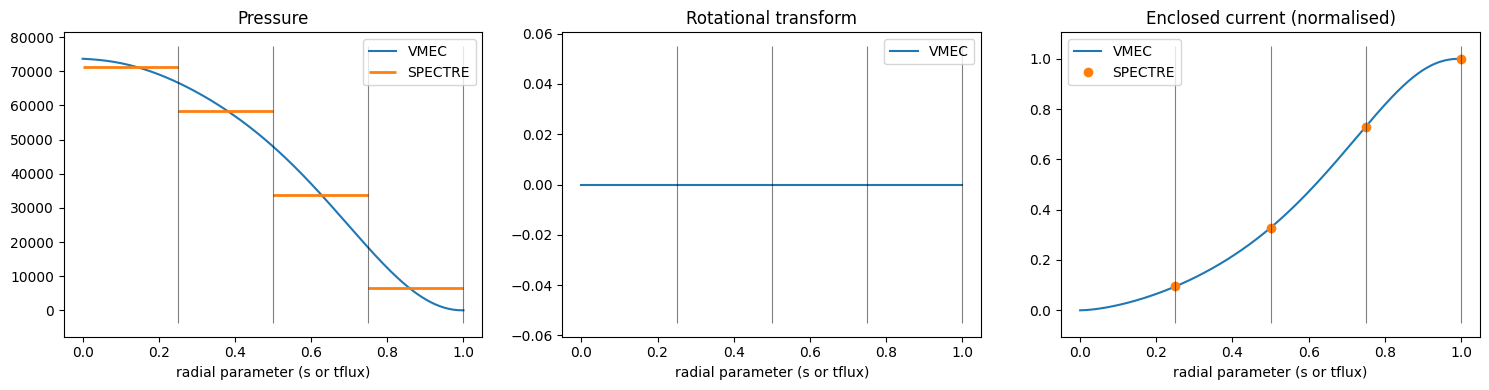

In [5]:
fig, axes = compare_vmec_spectre(vmec, params)
plt.show()

## Step 2 – NCSX coils

`get_data('ncsx')` returns `(base_curves, base_currents, ma, nfp, bs)` for one field period;
`bs` already includes all stellarator-symmetric copies.
`curpol` (μ₀ × net poloidal linking current) is computed automatically inside
`fix2free` from `bs.coils`.

In [6]:
_, _, _, _, bs = get_data("ncsx")
print(f"Number of coils (full torus): {len(bs.coils)}")

Number of coils (full torus): 18


## Step 3 – Build the computational boundary

The boundary extension is separated from the converter so you can tune or replace
the computational boundary independently.  Here we use `extend_via_normal(-0.1)`,
where the negative sign means *outward* in simsopt's convention.

Because NCSX is so strongly shaped, it is helpful to throw a few iterations of QFM minimization over it, because 

minor radius before condensation: 0.4971400147800294
Iteration     1: objective = 4.773225e+01
Iteration     2: objective = 4.670036e+01
Iteration     3: objective = 4.656796e+01
Iteration     4: objective = 4.650072e+01
Iteration     5: objective = 4.643871e+01
Iteration     6: objective = 4.639077e+01
Iteration     7: objective = 4.634622e+01
Iteration     8: objective = 4.631389e+01
Iteration     9: objective = 4.628563e+01
Iteration    10: objective = 4.625822e+01
Iteration    11: objective = 4.624014e+01
(Max error in fitting R or Z of points) / minor_radius: 1.001e-03
     message: Iteration limit reached
     success: False
      status: 9
         fun: 46.240142074677735
           x: [ 3.868e-03  1.190e-02 ... -6.267e-04 -3.404e-03]
         nit: 10
         jac: [ 6.418e-01  1.050e+00 ... -6.816e-07 -3.854e-06]
        nfev: 11
        njev: 11
 multipliers: [ 0.000e+00  0.000e+00 ...  0.000e+00  0.000e+00]
Time taken (s): 14.762215614318848


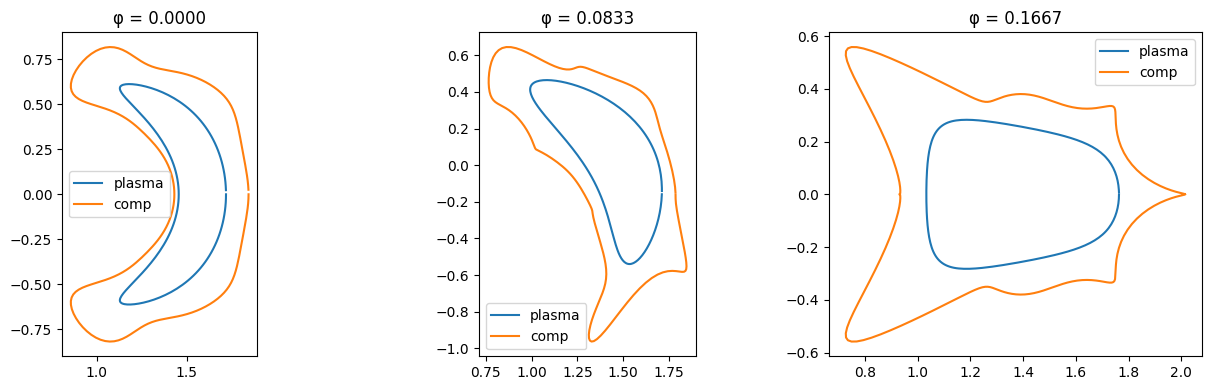

In [14]:
plasma_boundary = params_to_simsopt_boundary(params, which="plasma")
comp_boundary1 = plasma_boundary.copy()
comp_boundary1.extend_via_normal(-0.13)   # negative → outward

bs_tf = BiotSavart(bs.coils)


# make boundary a QFM surface
qfm = QfmResidual(comp_boundary1, bs)
qfm.J()


tf = ToroidalFlux(comp_boundary1, bs_tf)
tf_target = tf.J()

qfm_surface = QfmSurface(bs, comp_boundary1, tf, tf_target)

res = qfm_surface.minimize_qfm_penalty_constraints_LBFGS(tol=1e-12, maxiter=100)

newboundary, data = comp_boundary1.condense_spectrum(Fourier_continuation=False, maxiter=10)





# Plot original vs extended cross-sections
nfp = plasma_boundary.nfp
phis = [0.0, 1 / (4 * nfp), 1 / (2 * nfp)]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for phi, ax in zip(phis, axes):
    for surf, label in [(plasma_boundary, "plasma"), (newboundary, "comp")]:
        cs = surf.cross_section(phi=phi, thetas=200)
        R = np.sqrt(cs[:, 0] ** 2 + cs[:, 1] ** 2)
        ax.plot(R, cs[:, 2], label=label)
    ax.set_aspect("equal")
    ax.set_title(f"φ = {phi:.4f}")
    ax.legend()
fig.tight_layout()

## Step 4 – Convert to free boundary

In [15]:
freeb_params = fix2free(
    params, bs, newboundary, vacuum=False,
    filename="ncsx_volcur.toml",
)

nvol = freeb_params.physics.nvol
print(f"lfreebound : {freeb_params.physics.lfreebound}")
print(f"nvol       : {nvol}")
print(f"curpol     : {freeb_params.physics.curpol:.4g} T·m")
print(f"phiedge    : {freeb_params.physics.phiedge:.4g} Wb")
print(f"tflux[nvol-1:nvol+1] : {freeb_params.physics.tflux[nvol - 1 : nvol + 1]}")

# Sanity: plasma and comp boundaries must differ
rbc_diff = np.max(np.abs(freeb_params.physics.rbc - freeb_params.physics.rwc))
print(f"max|rbc - rwc| = {rbc_diff:.4g}  (should be > 0)")

lfreebound : 1
nvol       : 4
curpol     : 13.89 T·m
phiedge    : 0.5144 Wb
tflux[nvol-1:nvol+1] : [1.         2.46711575]
max|rbc - rwc| = 0.1414  (should be > 0)


## Step 5 – Mode spectrum and boundary cross-sections

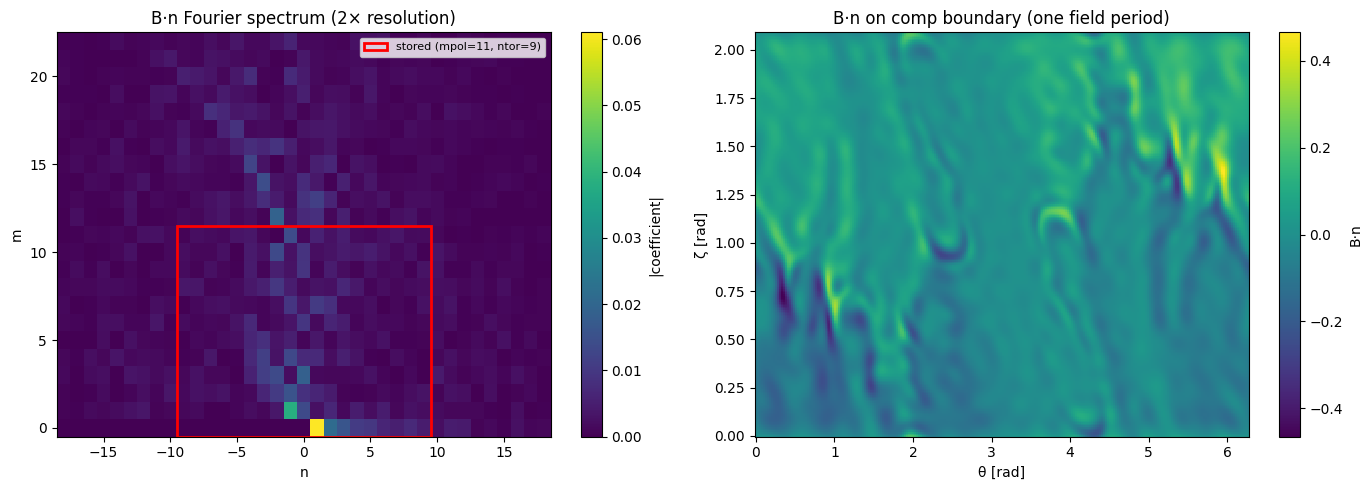

In [13]:
fig = plot_freeboundary_modes(bs, freeb_params, log_scale=False)
plt.show()

## Step 6 – Try running SPECTRE

A **fresh** `SPECTRE` object resets Fortran-side memory, so this should work even
if a fixed-boundary object was created in the same kernel above.

readin :            : 
readin :       0.00 : Igeometry=  3 ; enforce_stell_sym=  T ; Lreflect=  0 ; Lbdybnzero= T 
readin :            : Lfreebound=  1 ; phiedge=  5.143860000000000E-01 ; curtor=  6.137925480624758E+04 ; curpol=  1.388747893757724E+01 
readin :            : gamma=  0.000000000000000E+00 
readin :            : Nfp=  3 ; Nvol=  4 ; Mvol=  5 ; Mpol= 11 ; Ntor=  9 
readin :            : pscale=  1.00000E+00 ; Ladiabatic= 0 ; Lconstraint=  3 ; mupf: tol,its=  1.00E-14,   8 
readin :            : Lrad = 15,15,15,15,15,
readin :            : 
readin :       0.00 : Linitialize=  0 ;LautoinitBn=  0 ; Lzerovac= 0 ; Ndiscrete= 2 
readin :            : Nquad=  -1 ; iMpol=  -4 ; iNtor=  -4 
readin :            : 
readin :            : 
readin :            : escale=  0.00000E+00 ; opsilon=  1.00000E+00 ; pcondense=  2.000 ; epsilon=  0.00000E+00 ; wpoloidal        = 1.0000 ; upsilon=  1.00000E+00 
readin :            : mfreeits=   0 ; gBntol=  1.00000E-06 ; gBnbld=  6.66000E-01 
rea

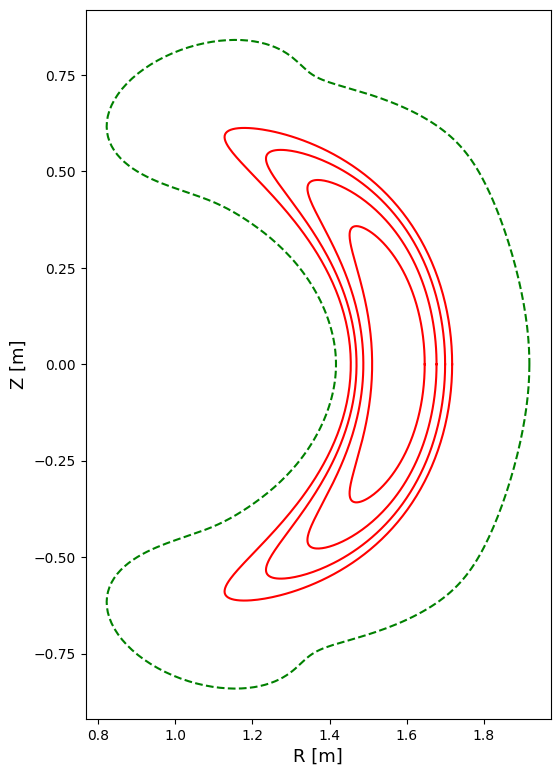

In [10]:
spectre = SPECTRE.from_input_params(freeb_params)
spectre.